<a href="https://colab.research.google.com/github/SattikBhaumik/CS156/blob/main/CS156_Session_16.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Dimensionality reduction 1: PCA

##Basic Question

In [ ]:
import numpy as np

def pca_factorization(A, k=2):
    #centering the data
    Z = A - np.mean(A, axis=0)

    #calculating covariance matrix
    C = np.cov(Z, rowvar=False)

    #calculate eigenvalues and eigenvectors
    eigenvalues, eigenvectors = np.linalg.eigh(C)

    #sort from largest to smallest
    indices = np.argsort(eigenvalues)[::-1]
    eigenvectors = eigenvectors[:, indices]

    #selection of k principal components
    W = eigenvectors[:, :k]

    #matrix multiplication
    return Z @ W


# Minerva grades
A = np.array([
    [5, 3, 5],
    [5, 5, 1],
    [3, 3, 3],
    [3, 3, 5],
    [1, 1, 1]
])

result = pca_factorization(A)
print(np.round(result, 3))

[[ 2.291  0.911]
 [ 0.666 -3.179]
 [-0.262  0.154]
 [ 0.98   1.683]
 [-3.674  0.43 ]]


##Core Question

In [ ]:
import kagglehub
path = kagglehub.dataset_download("zalando-research/fashionmnist")
print("Path to dataset files:", path)

Using Colab cache for faster access to the 'fashionmnist' dataset.
Path to dataset files: /kaggle/input/fashionmnist


Original shape: (200, 784)
Number of eigenvectors: 69
Reduced shape: (200, 69)
Variance retained: 0.9508079664129122


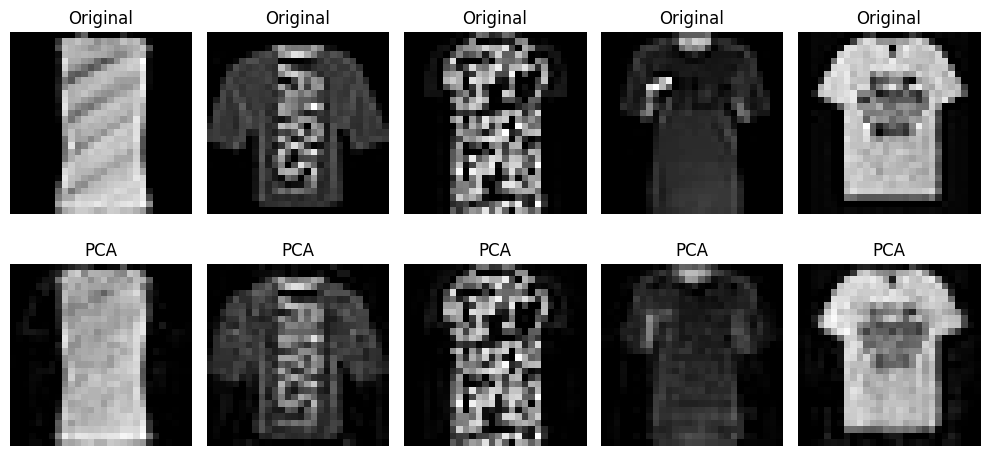

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

df = pd.read_csv("/kaggle/input/fashionmnist/fashion-mnist_train.csv")

#100 T-shirts and 100 shirts
tshirts = df[df["label"] == 0].sample(100, random_state=42)
shirts = df[df["label"] == 6].sample(100, random_state=42)
data = pd.concat([tshirts, shirts])

#separating images and labels
X = data.drop(columns=["label"]).to_numpy() / 255.0
y = data["label"].to_numpy()
print("Original shape:", X.shape)

#PCA to retain 95% variance
pca = PCA(n_components=0.95)
X_reduced = pca.fit_transform(X)

print("Number of eigenvectors:", pca.n_components_)
print("Reduced shape:", X_reduced.shape)
print("Variance retained:", sum(pca.explained_variance_ratio_))

#image reconstruction
X_reconstructed = pca.inverse_transform(X_reduced)

#comparing original and reconstructed images
fig, axes = plt.subplots(2, 5, figsize=(10, 5))

for i in range(5):
    axes[0, i].imshow(X[i].reshape(28, 28), cmap="gray")
    axes[0, i].set_title("Original")
    axes[0, i].axis("off")

    axes[1, i].imshow(X_reconstructed[i].reshape(28, 28),
                      cmap="gray", vmin=0, vmax=1)
    axes[1, i].set_title("PCA")
    axes[1, i].axis("off")

plt.tight_layout()
plt.show()

##Extension Question

Original shape: (15, 12288)
Number of eigenvectors: 7
Reduced shape: (15, 7)
Variance retained: 0.9673899956339567


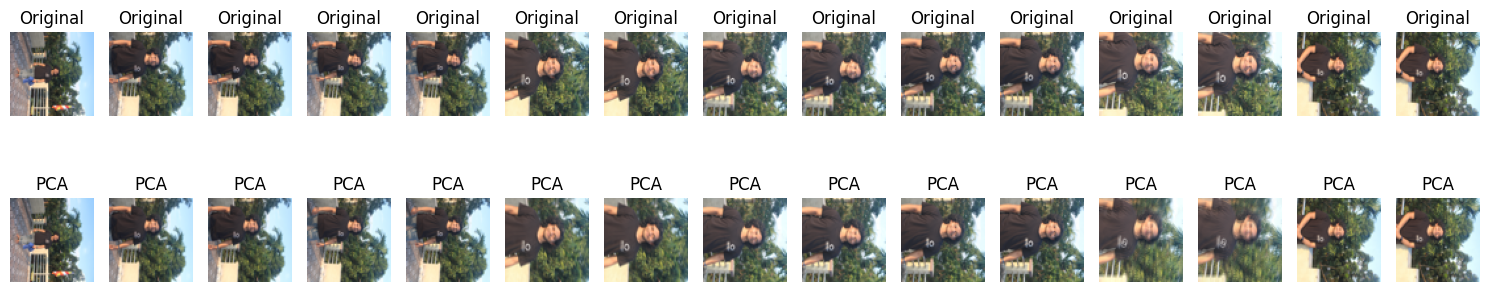

In [ ]:
from PIL import Image
from pathlib import Path

images = []
for file in sorted(Path("/content/camera_photos").glob("*")):
    try:
        img = Image.open(file).convert("RGB")
        img = img.resize((64, 64))
        images.append(np.array(img).flatten() / 255.0)
    except Exception:
        continue

X = np.array(images)
print("Original shape:", X.shape)

#PCA to retain 95% variance
pca = PCA(n_components=0.95)
X_reduced = pca.fit_transform(X)
print("Number of eigenvectors:", pca.n_components_)
print("Reduced shape:", X_reduced.shape)
print("Variance retained:", sum(pca.explained_variance_ratio_))

#image reconstruction
X_reconstructed = pca.inverse_transform(X_reduced)

#comparing original and reconstructed images
fig, axes = plt.subplots(2, len(X), figsize=(15, 4))

for i in range(len(X)):
    original = X[i].reshape(64, 64, 3)
    reconstructed = X_reconstructed[i].reshape(64, 64, 3)

    axes[0, i].imshow(original)
    axes[0, i].set_title("Original")
    axes[0, i].axis("off")

    axes[1, i].imshow(np.clip(reconstructed, 0, 1))
    axes[1, i].set_title("PCA")
    axes[1, i].axis("off")

plt.tight_layout()
plt.show()